# 03 — EDA cho mô hình kết hợp thông tin rượu và TF-IDF

**Mục tiêu:** hiểu quan hệ giá–điểm, sự khác biệt giữa các nhóm sản phẩm và cấu trúc review để chuẩn bị một mô hình hồi quy `points`.

Thông tin sản phẩm + TF-IDF unigram/bigram → ghép đặc trưng → Ridge là **thiết kế dự kiến**, chưa huấn luyện. Không có embedding, kiểm định chính thức hay metric mô hình trong notebook này.

**Phạm vi:** audit trên cleaned data; mọi phân tích chi tiết giá, điểm, metadata và review dùng train. Validation/test chỉ được đọc cột review để audit trùng văn bản. Điểm phản ánh người đánh giá, không phải chất lượng khách quan.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.create_eda_plots import run_eda
OUT = ROOT / 'outputs/eda'
tables = run_eda(OUT)
def show_figure(name):
    display(Image(filename=str(OUT / 'figures' / f'{name}.png'), width=900))


## 1. Audit và chọn mẫu

Dữ liệu sạch giữ các dòng thiếu giá, không tự thay bằng giá ước tính. Bảng audit mô tả mọi cột của cleaned data; nhãn phân loại quy ước như `Unknown` không được tính là NaN.

In [2]:
display(tables['sample_counts'])
display(tables['audit_missing'])
display(Markdown("**Nhận xét:** cleaned data và mẫu có giá là hai phạm vi khác nhau. "
    "Mẫu train thuộc các dòng có giá; vì vậy số giá thiếu trong bảng nhóm train bằng 0, "
    "không có nghĩa toàn bộ nguồn dữ liệu không thiếu giá. Mẫu này có thể khác nhóm bị thiếu giá."))

,sample,rows
0,cleaned,119988
1,observed_price,111593
2,missing_price,8395
3,train,78106


,column,dtype,missing,missing_pct
0,country,str,0,0.000000
1,description,str,0,0.000000
2,designation,str,0,0.000000
3,points,int64,0,0.000000
4,price,float64,8395,6.996533
5,province,str,0,0.000000
6,region_1,str,0,0.000000
7,region_2,str,0,0.000000
8,taster_name,str,0,0.000000
9,taster_twitter_handle,str,0,0.000000


**Nhận xét:** cleaned data và mẫu có giá là hai phạm vi khác nhau. Mẫu train thuộc các dòng có giá; vì vậy số giá thiếu trong bảng nhóm train bằng 0, không có nghĩa toàn bộ nguồn dữ liệu không thiếu giá. Mẫu này có thể khác nhóm bị thiếu giá.

## 2. Phân bố điểm review

Quan sát phạm vi và mức tập trung của `points`. Phân bố hẹp có thể khiến dự đoán quanh trung tâm trông tốt; chưa có bằng chứng mô hình học được quan hệ chỉ từ biểu đồ.

,count,mean,std,min,25%,50%,75%,max
points,78106.0,88.415973,3.103525,80.000000,86.000000,88.000000,91.0000,100.000000
price,78106.0,35.656032,41.364469,4.000000,17.000000,25.000000,42.0000,2500.000000
log_price,78106.0,3.359111,0.637869,1.609438,2.890372,3.258097,3.7612,7.824446
vintage_year,75426.0,2010.641622,3.631384,1980.000000,2009.000000,2011.000000,2013.0000,2017.000000


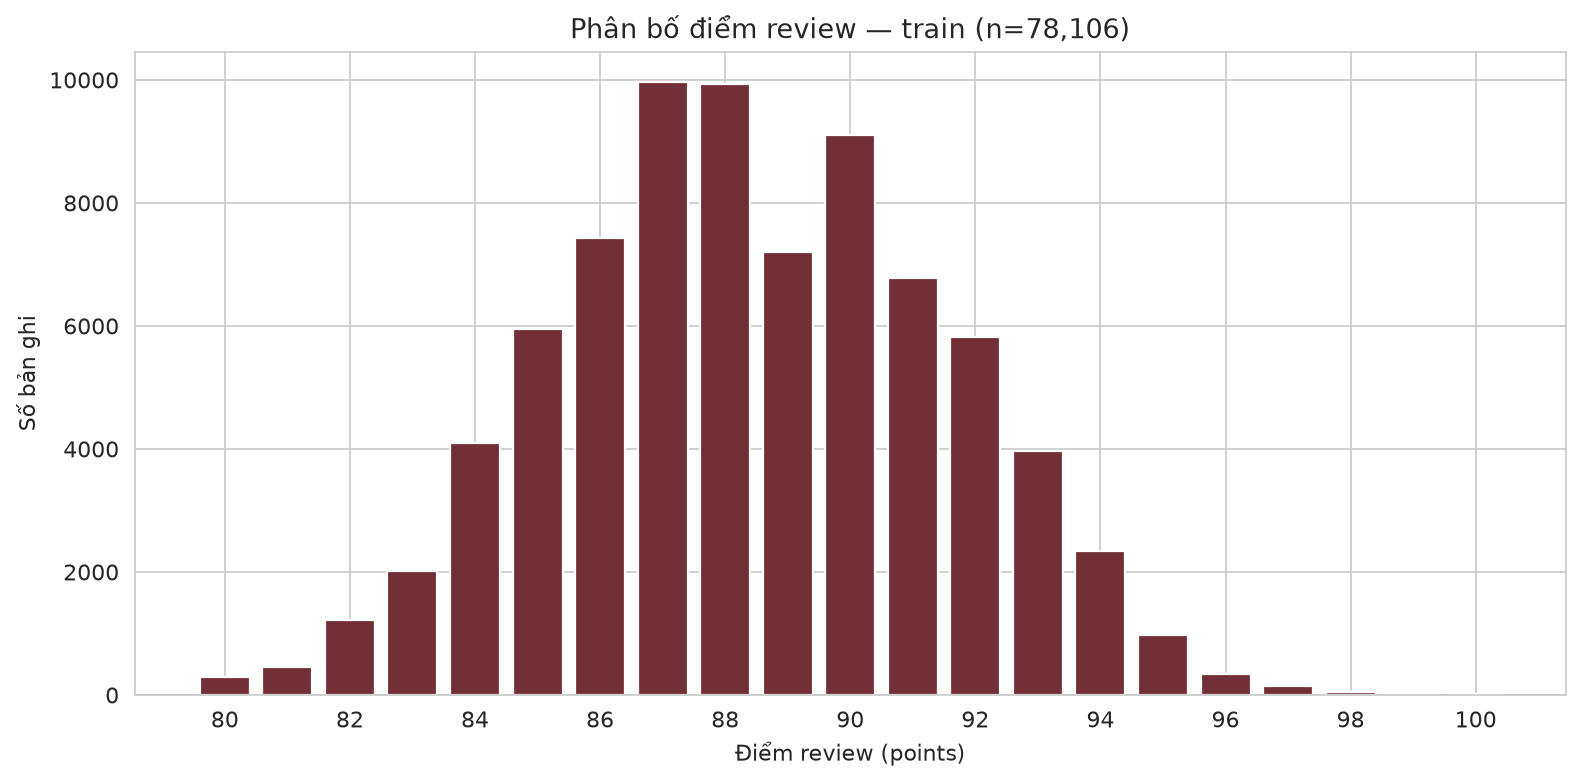

**Nhận xét trên train:** điểm trung bình 88.42, độ lệch chuẩn 3.10, phạm vi 80–100. Đây là điểm của các review đã được chọn vào dữ liệu, không đại diện toàn bộ thị trường.

In [3]:
display(tables['numeric_summary'])
show_figure('01_points_distribution')
s = tables['numeric_summary']
display(Markdown(f"**Nhận xét trên train:** điểm trung bình {s.loc['points', 'mean']:.2f}, "
    f"độ lệch chuẩn {s.loc['points', 'std']:.2f}, phạm vi "
    f"{s.loc['points', 'min']:.0f}–{s.loc['points', 'max']:.0f}. "
    "Đây là điểm của các review đã được chọn vào dữ liệu, không đại diện toàn bộ thị trường."))

## 3. Giá và quan hệ giá–điểm

Giữ đuôi giá cao hợp lệ. Histogram giá gốc dùng toàn phạm vi; log1p giúp quan sát phần giá phổ biến rõ hơn. Scatter hiển thị tối đa 15.000 dòng lấy mẫu seed 42; bảng dùng toàn bộ train. Tứ phân vị được xác định riêng trên train.

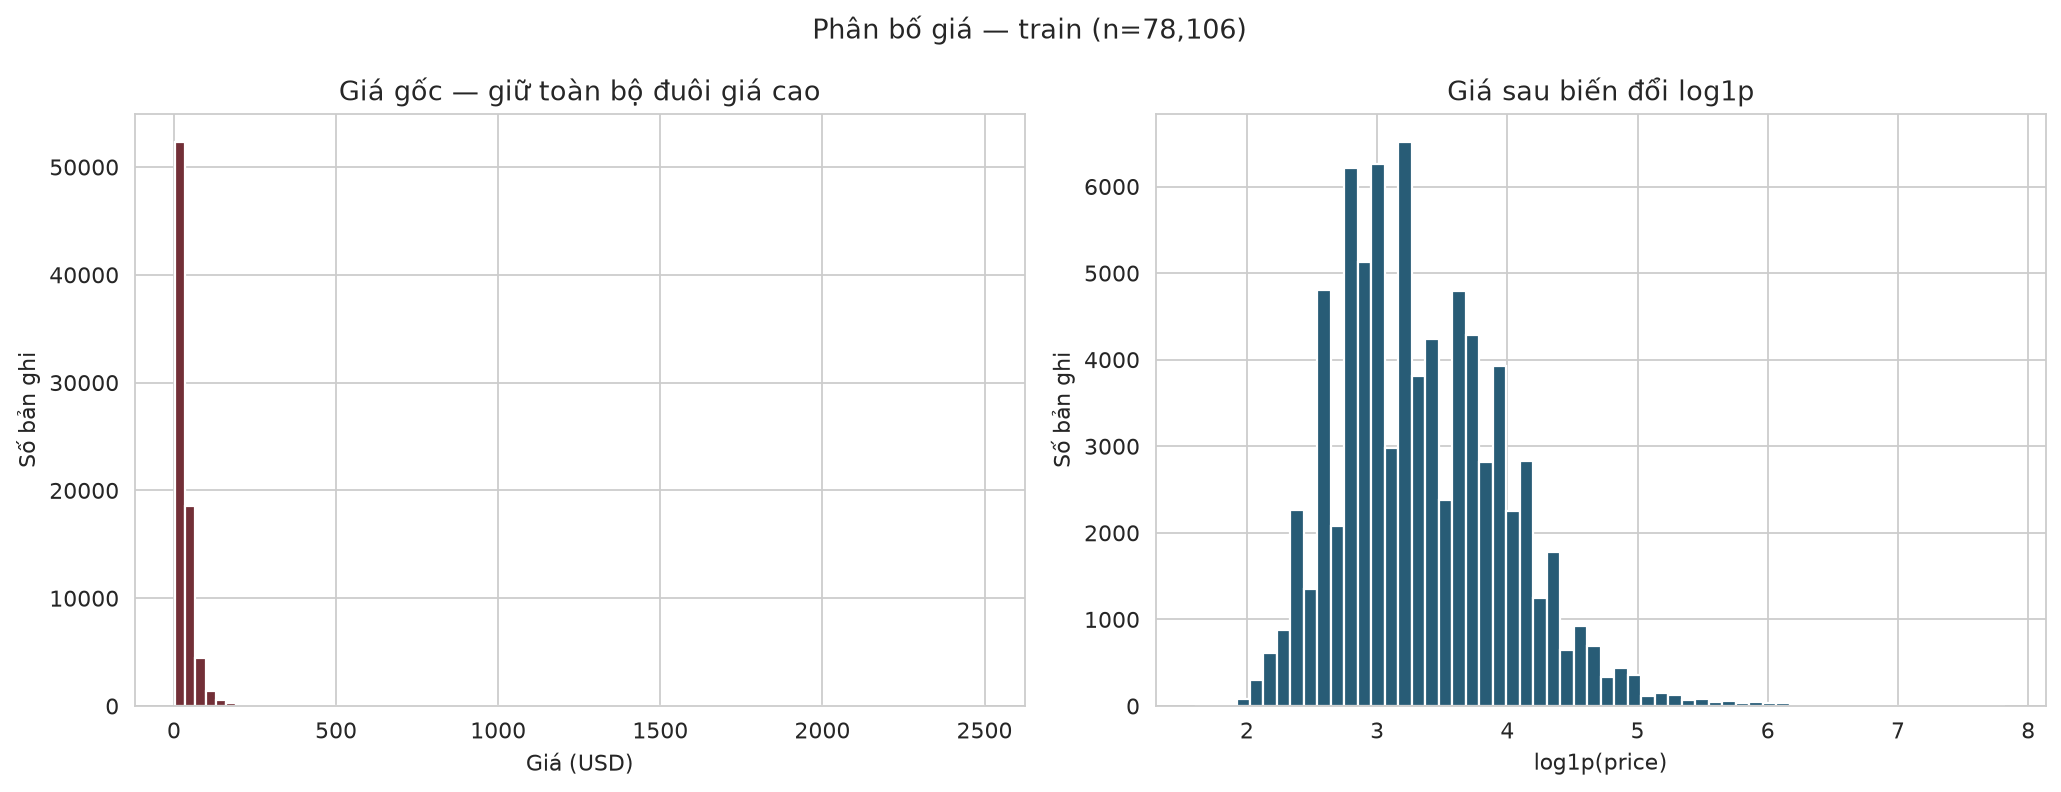

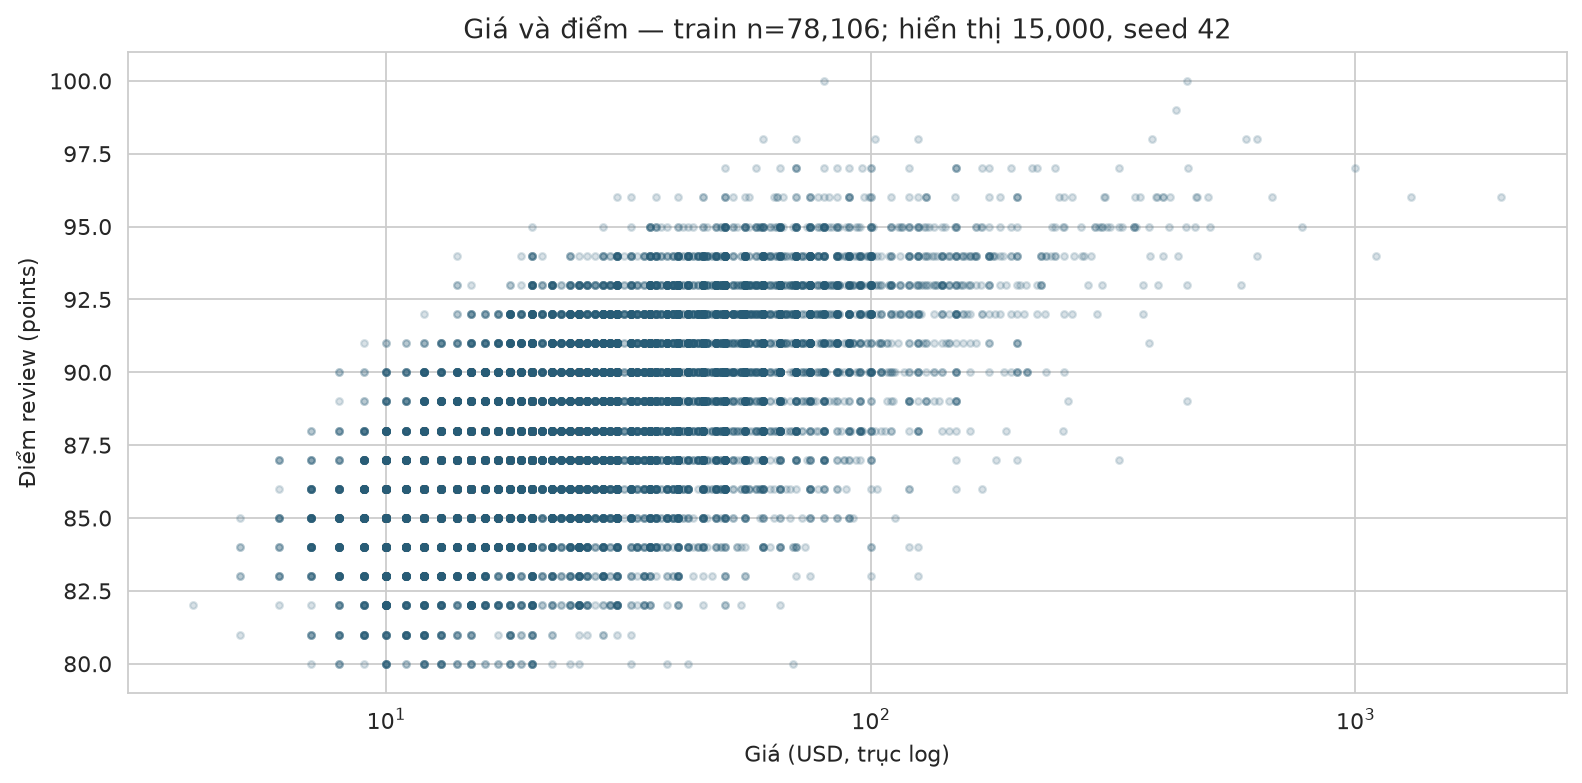

,rows,price_median,points_median,points_mean
price_interval_usd,,,,
"(3.999, 17.0]",20562,13.0,86.0,86.081072
"(17.0, 25.0]",18932,21.0,88.0,87.729823
"(25.0, 42.0]",19297,33.0,89.0,88.975177
"(42.0, 2500.0]",19315,60.0,91.0,91.015480


**Nhận xét:** trên train, giá trung vị là 25 USD, giá trung bình 35.66 USD, tối đa 2500 USD. Điểm trung vị từ khoảng giá thấp nhất đến cao nhất lần lượt là 86.0 và 91.0. Chênh lệch mô tả không chứng minh giá gây ra điểm cao; log giá không bảo đảm phân phối chuẩn.

In [4]:
show_figure('02_price_distribution')
show_figure('03_price_points')
display(tables['price_tiers'])
tiers = tables['price_tiers']
display(Markdown(f"**Nhận xét:** trên train, giá trung vị là {s.loc['price', '50%']:.0f} USD, "
    f"giá trung bình {s.loc['price', 'mean']:.2f} USD, tối đa {s.loc['price', 'max']:.0f} USD. "
    f"Điểm trung vị từ khoảng giá thấp nhất đến cao nhất lần lượt là "
    f"{tiers.iloc[0].points_median:.1f} và {tiers.iloc[-1].points_median:.1f}. "
    "Chênh lệch mô tả không chứng minh giá gây ra điểm cao; log giá không bảo đảm phân phối chuẩn."))

## 4. Quốc gia, vùng và giống nho

Bảng CSV giữ mọi nhóm và số giá thiếu; biểu đồ hiển thị tối đa 10 nhóm đông nhất có ít nhất 100 dòng. Loại nhãn placeholder khỏi so sánh điểm. Trung bình và trung vị không phải bảng xếp hạng chất lượng; các nhóm có thể khác về giá, người chấm và cách tuyển chọn.

### country

,rows,missing_price,price_median,points_mean,points_median
country,,,,,
US,35165,0,30.0,88.560273,88.0
France,11397,0,25.0,88.762394,89.0
Italy,10755,0,28.0,88.639888,88.0
Spain,4280,0,18.0,87.235280,87.0
Portugal,3150,0,17.0,88.382222,88.0
Chile,2958,0,15.0,86.454023,86.0
Argentina,2482,0,17.0,86.650282,87.0
Austria,1754,0,25.0,90.259407,90.0
Australia,1515,0,21.0,88.570957,89.0


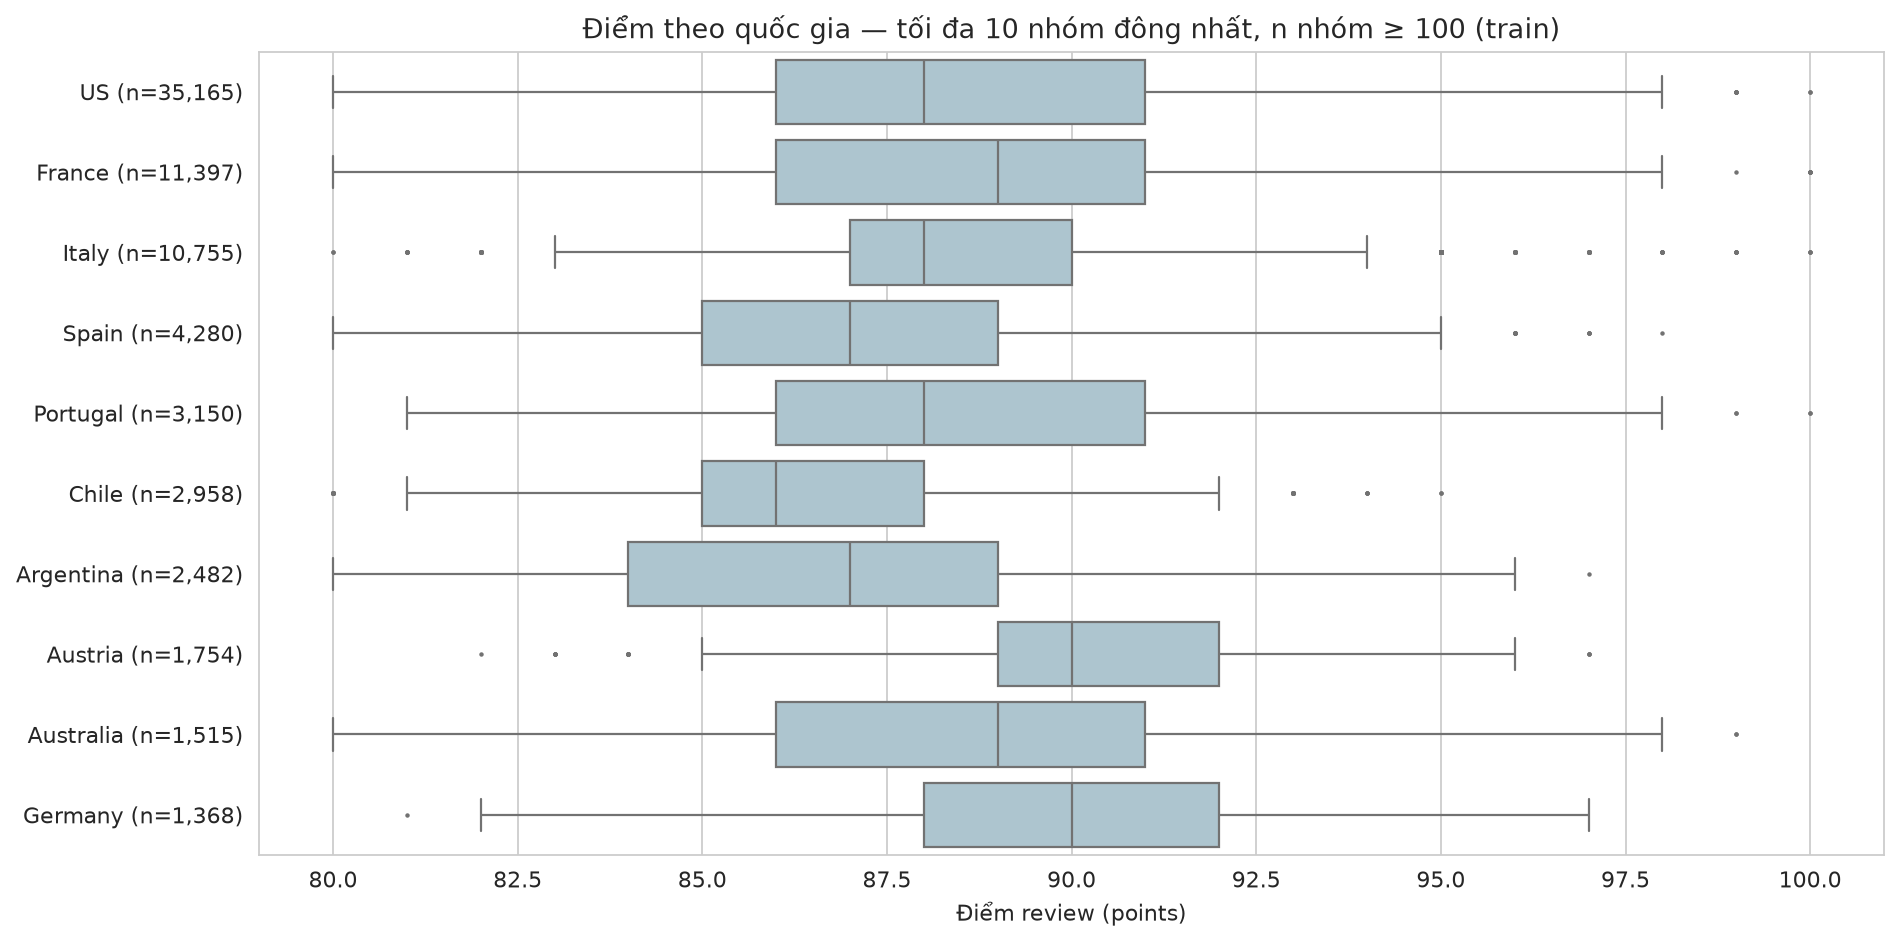

**Nhận xét:** country có 43 nhóm trên train; nhóm đông nhất là **US**, 35,165 bản ghi. Phân bố mẫu không đồng đều. Chỉ so sánh điểm nhóm đủ mẫu; chưa kết luận khác biệt có ý nghĩa thống kê.

### province

,rows,missing_price,price_median,points_mean,points_median
province,,,,,
California,23424,0,32.0,88.624744,89.0
Washington,5560,0,29.0,88.978777,89.0
Oregon,3418,0,30.0,89.059977,89.0
Tuscany,3250,0,35.0,89.240923,89.0
Bordeaux,2569,0,20.0,87.998054,88.0
Northern Spain,2476,0,19.0,87.359451,87.0
Mendoza Province,2136,0,17.0,86.769195,87.0
Burgundy,2022,0,43.0,89.696835,90.0
Piedmont,1984,0,49.0,89.612903,90.0


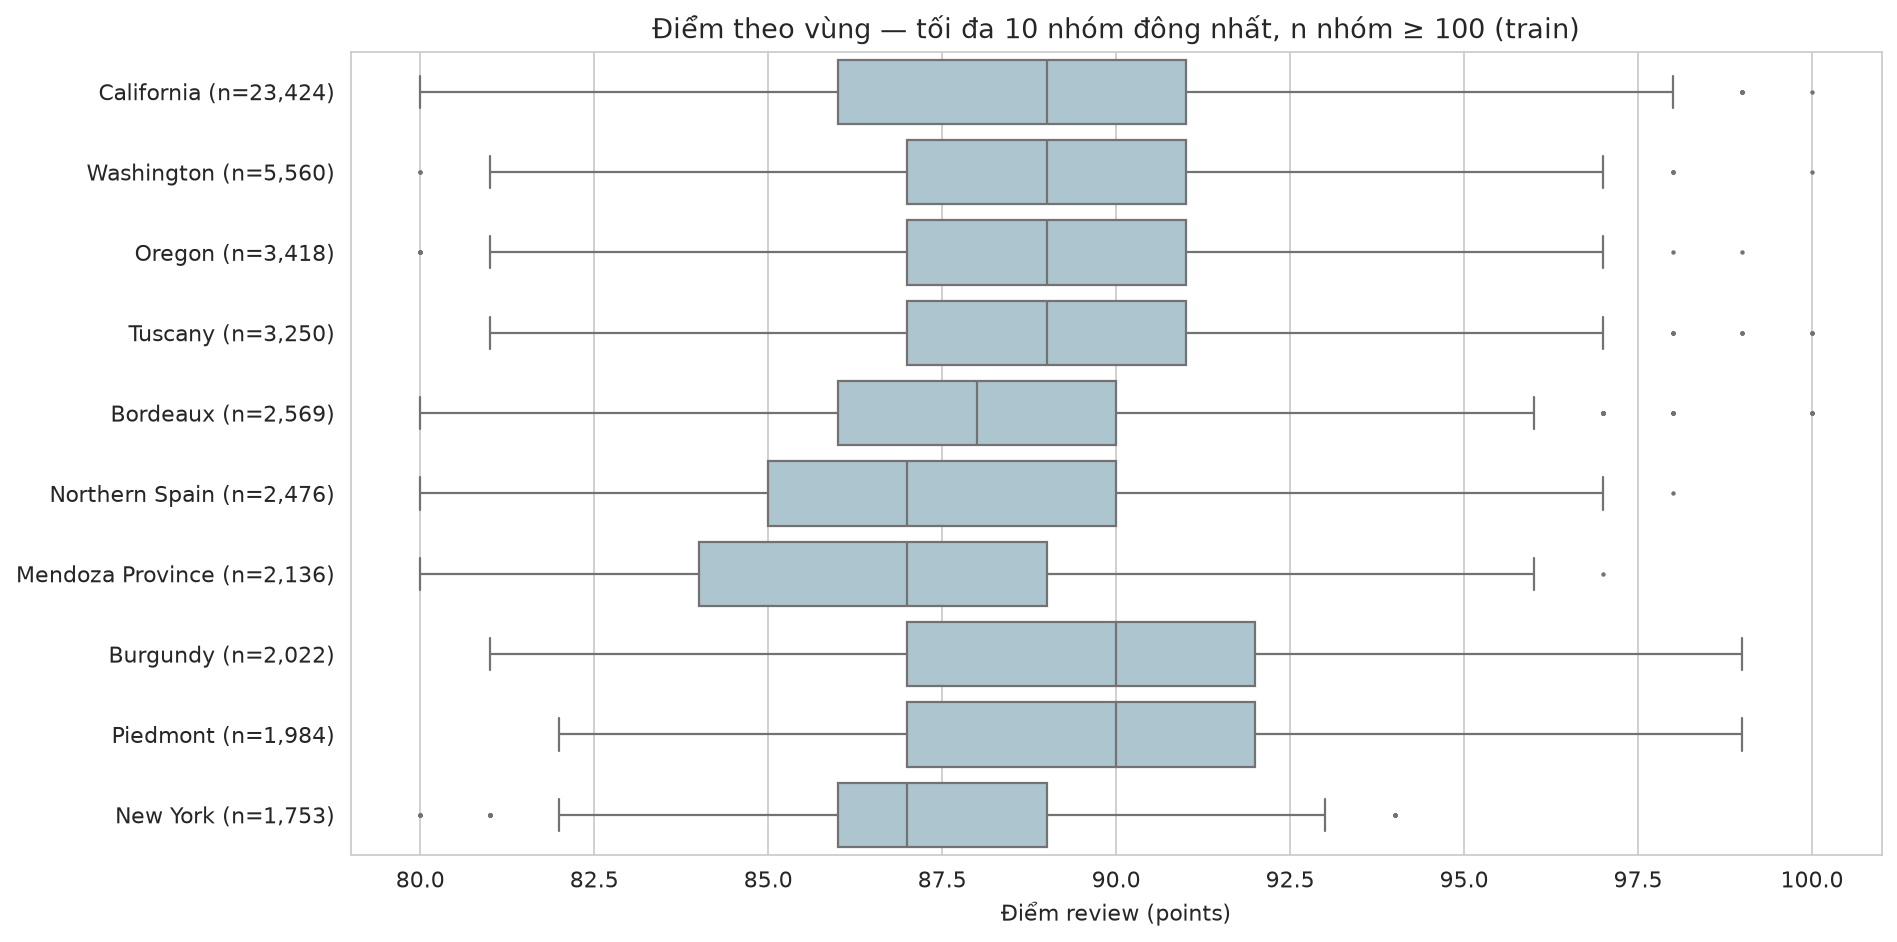

**Nhận xét:** province có 402 nhóm trên train; nhóm đông nhất là **California**, 23,424 bản ghi. Phân bố mẫu không đồng đều. Chỉ so sánh điểm nhóm đủ mẫu; chưa kết luận khác biệt có ý nghĩa thống kê.

### variety

,rows,missing_price,price_median,points_mean,points_median
variety,,,,,
Pinot Noir,8254,0,42.0,89.455052,90.0
Chardonnay,7196,0,26.0,88.303224,88.0
Cabernet Sauvignon,6128,0,36.0,88.602154,88.0
Red Blend,5452,0,28.0,88.370323,88.0
Bordeaux-style Red Blend,3436,0,30.0,88.829453,89.0
Riesling,3224,0,22.0,89.480459,90.0
Sauvignon Blanc,3103,0,18.0,87.321947,87.0
Syrah,2637,0,35.0,89.253697,90.0
Rosé,2072,0,16.0,86.788127,87.0


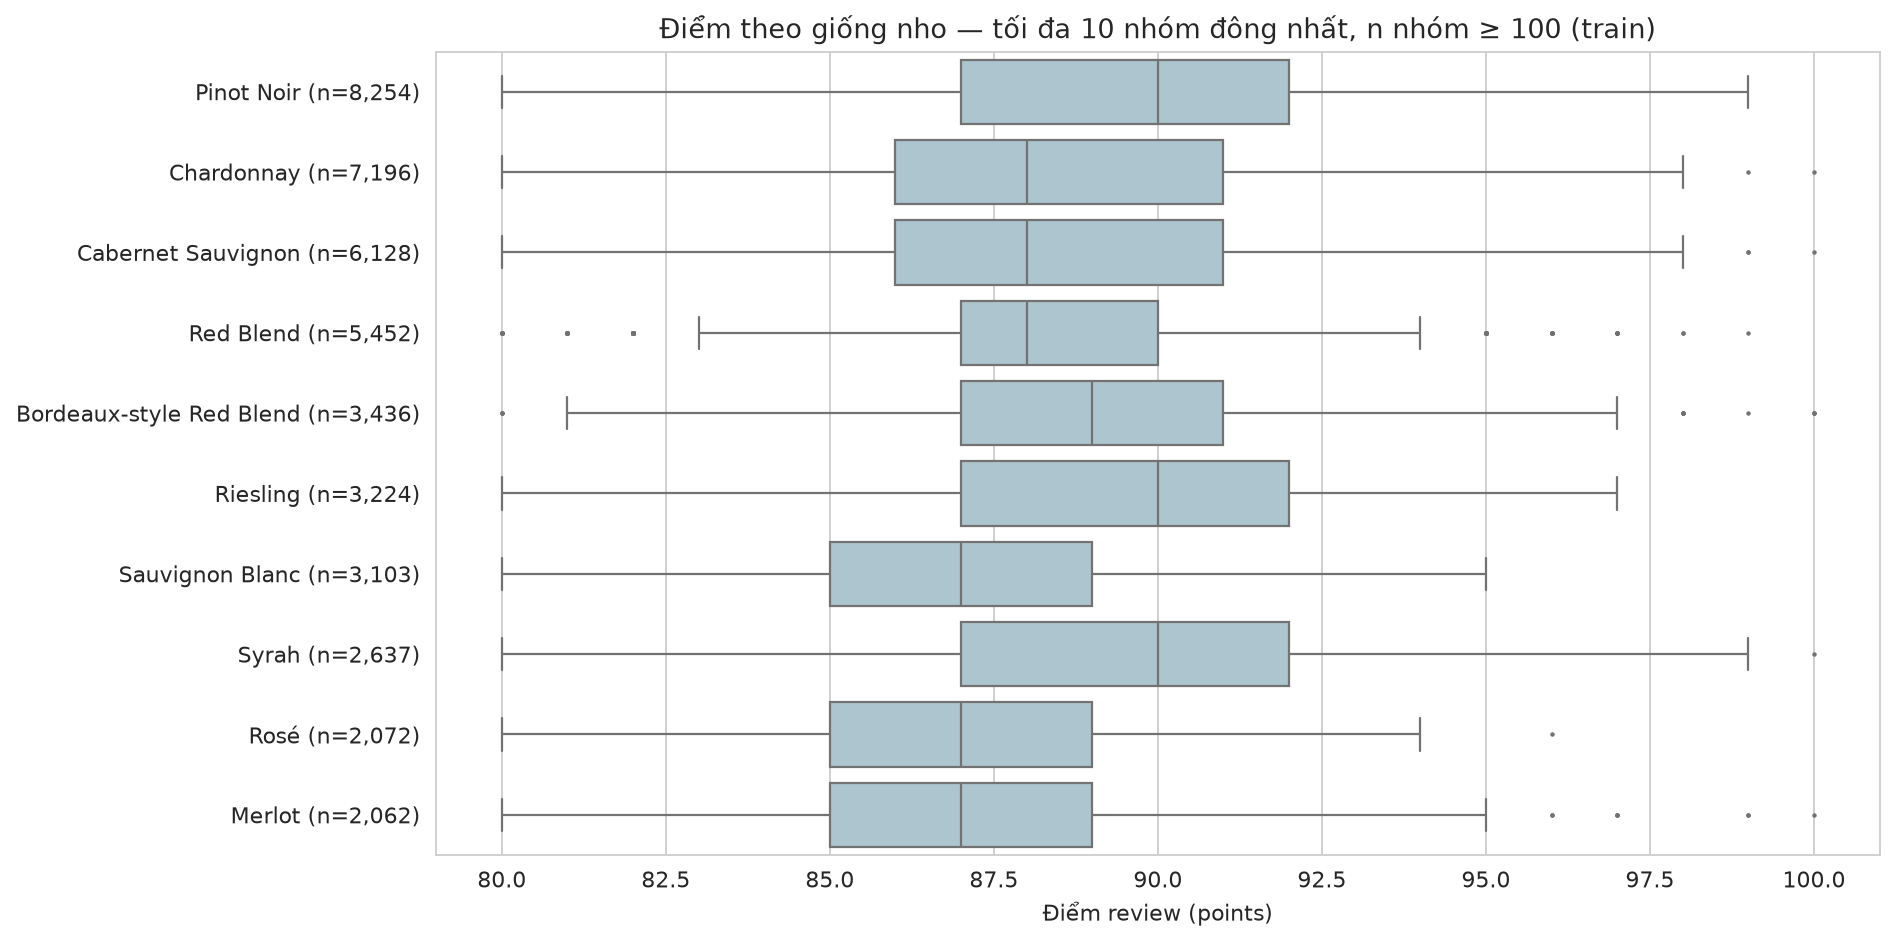

**Nhận xét:** variety có 637 nhóm trên train; nhóm đông nhất là **Pinot Noir**, 8,254 bản ghi. Phân bố mẫu không đồng đều. Chỉ so sánh điểm nhóm đủ mẫu; chưa kết luận khác biệt có ý nghĩa thống kê.

In [5]:
for column in ['country', 'province', 'variety']:
    display(Markdown(f"### {column}"))
    display(tables[f'groups_{column}'].head(10))
    show_figure(f'04_{column}_points')
    groups = tables[f'groups_{column}']
    display(Markdown(f"**Nhận xét:** {column} có {len(groups):,} nhóm trên train; "
        f"nhóm đông nhất là **{groups.index[0]}**, {int(groups.iloc[0]['rows']):,} bản ghi. "
        "Phân bố mẫu không đồng đều. Chỉ so sánh điểm nhóm đủ mẫu; chưa kết luận khác biệt có ý nghĩa thống kê."))

## 5. Đặc điểm review

Đếm từ theo khoảng trắng để mô tả độ dài. Review dưới 10 từ chỉ được gắn cờ, không tự động xóa.

Tần suất unigram/bigram dùng `CountVectorizer` trên train, giữ stopword và từ phủ định. Đây là thống kê mô tả, **không phải TF-IDF đã huấn luyện hay hệ số ảnh hưởng đến điểm**. Do giữ stopword, từ chức năng có thể đứng đầu; không mặc định đó là từ khen/chê.

,rows,empty_reviews,under_10_words,flagged_non_informative,median_words,min_words,max_words
0,78106,0,29,29,40.0,3,135


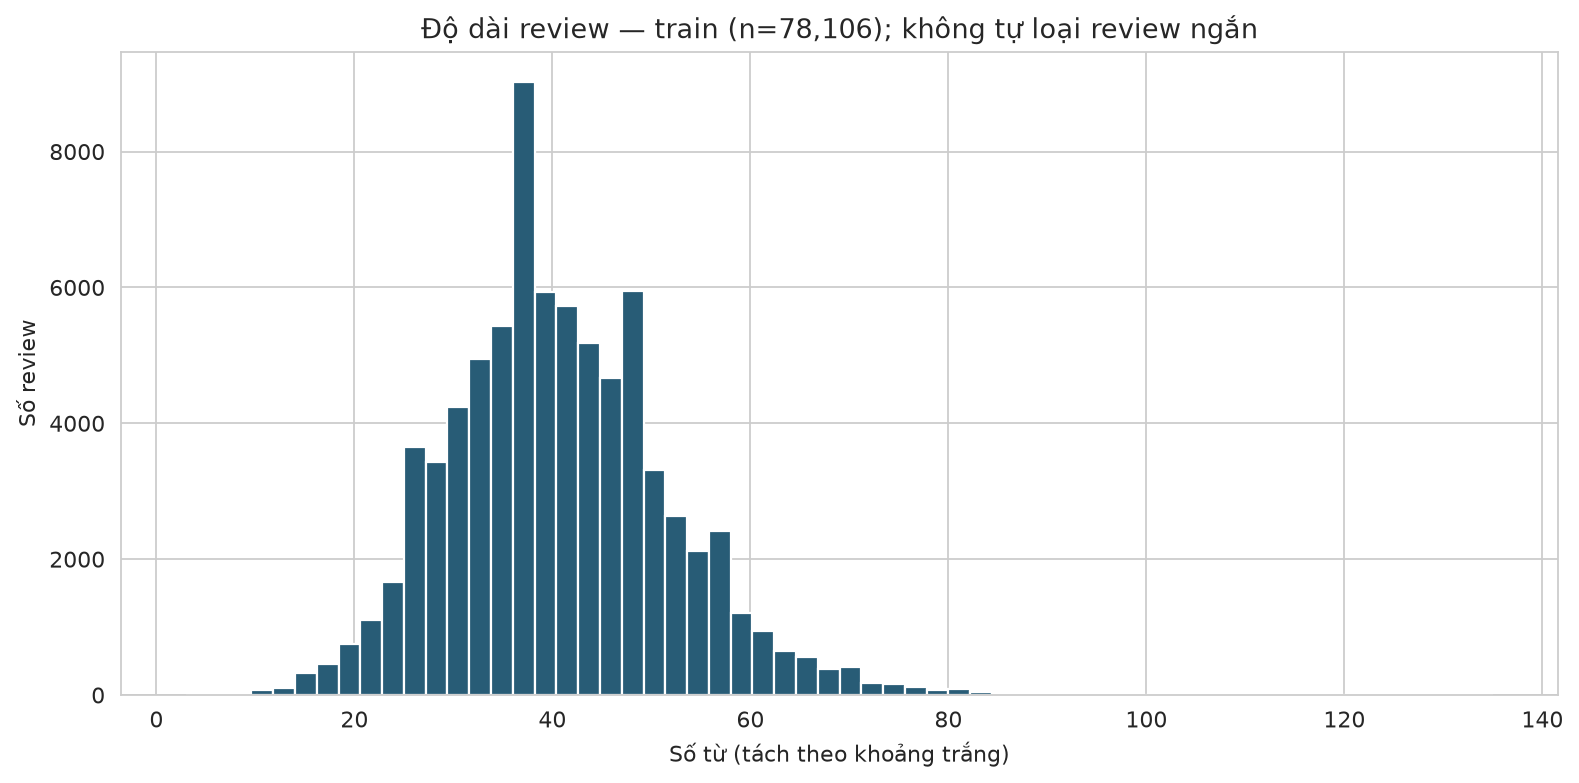

,term,occurrences,documents
0,and,212131,76661
1,the,133090,63004
2,of,104915,60091
3,with,73011,51486
4,this,68666,59263
5,is,57293,41695
6,it,52267,39262
7,wine,46615,37783
8,flavors,38951,37020
9,in,38594,29912


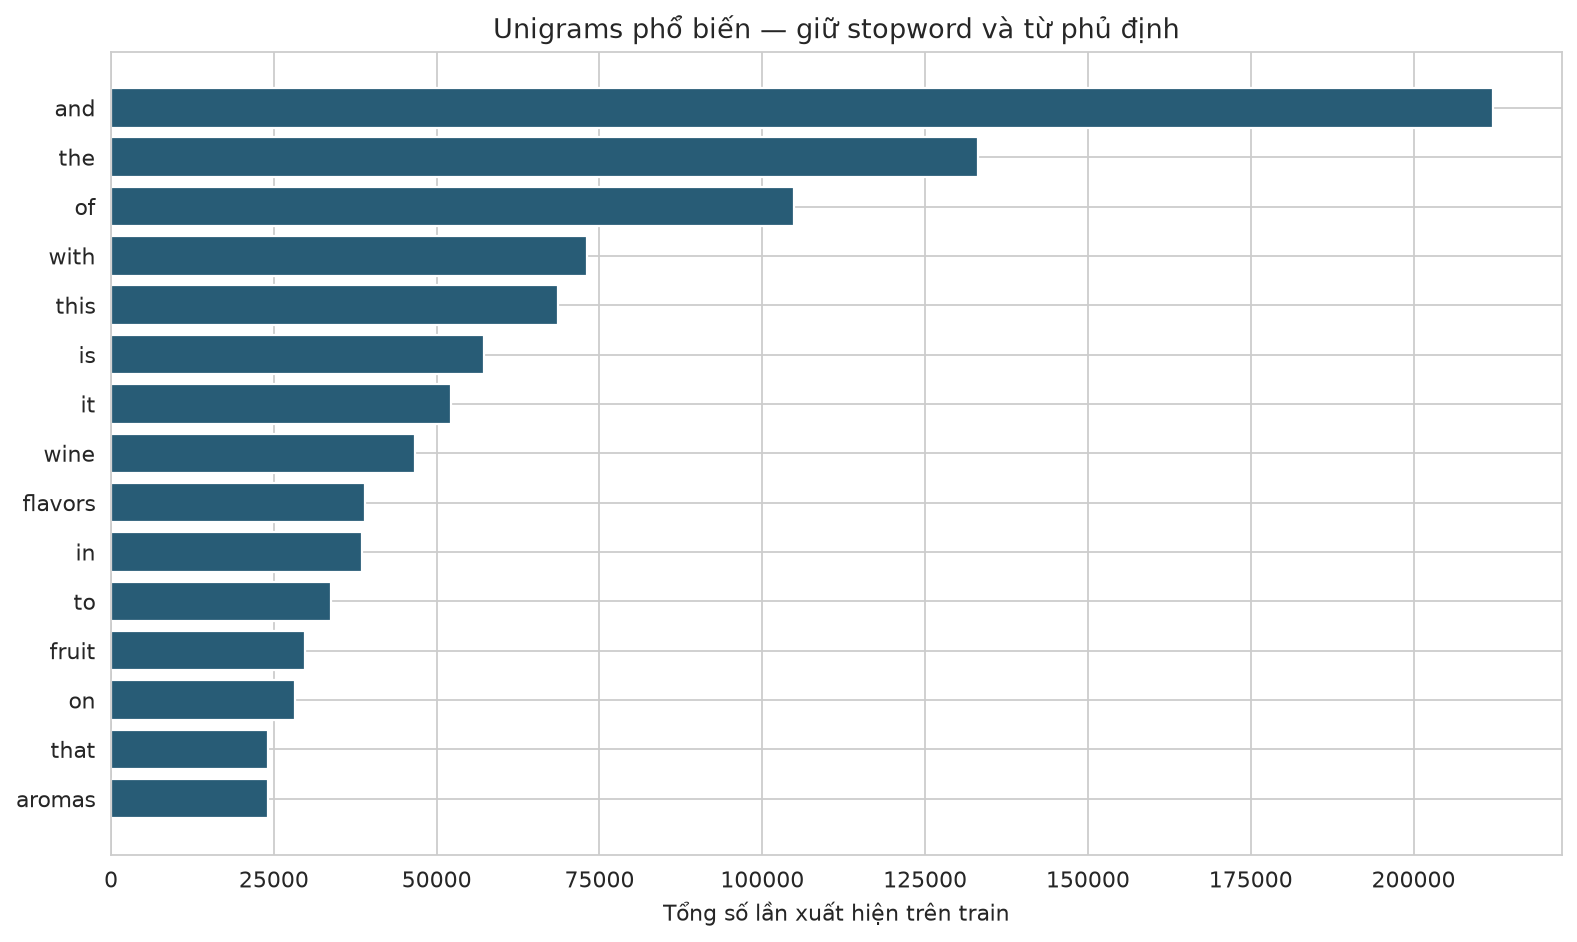

,term,occurrences,documents
0,on the,20518,17461
1,the palate,14614,14427
2,this is,14586,14056
3,aromas of,10851,10833
4,the finish,10604,10582
5,this wine,10412,10218
6,in the,9763,9175
7,flavors of,9752,9674
8,the wine,9187,8694
9,the nose,8169,8093


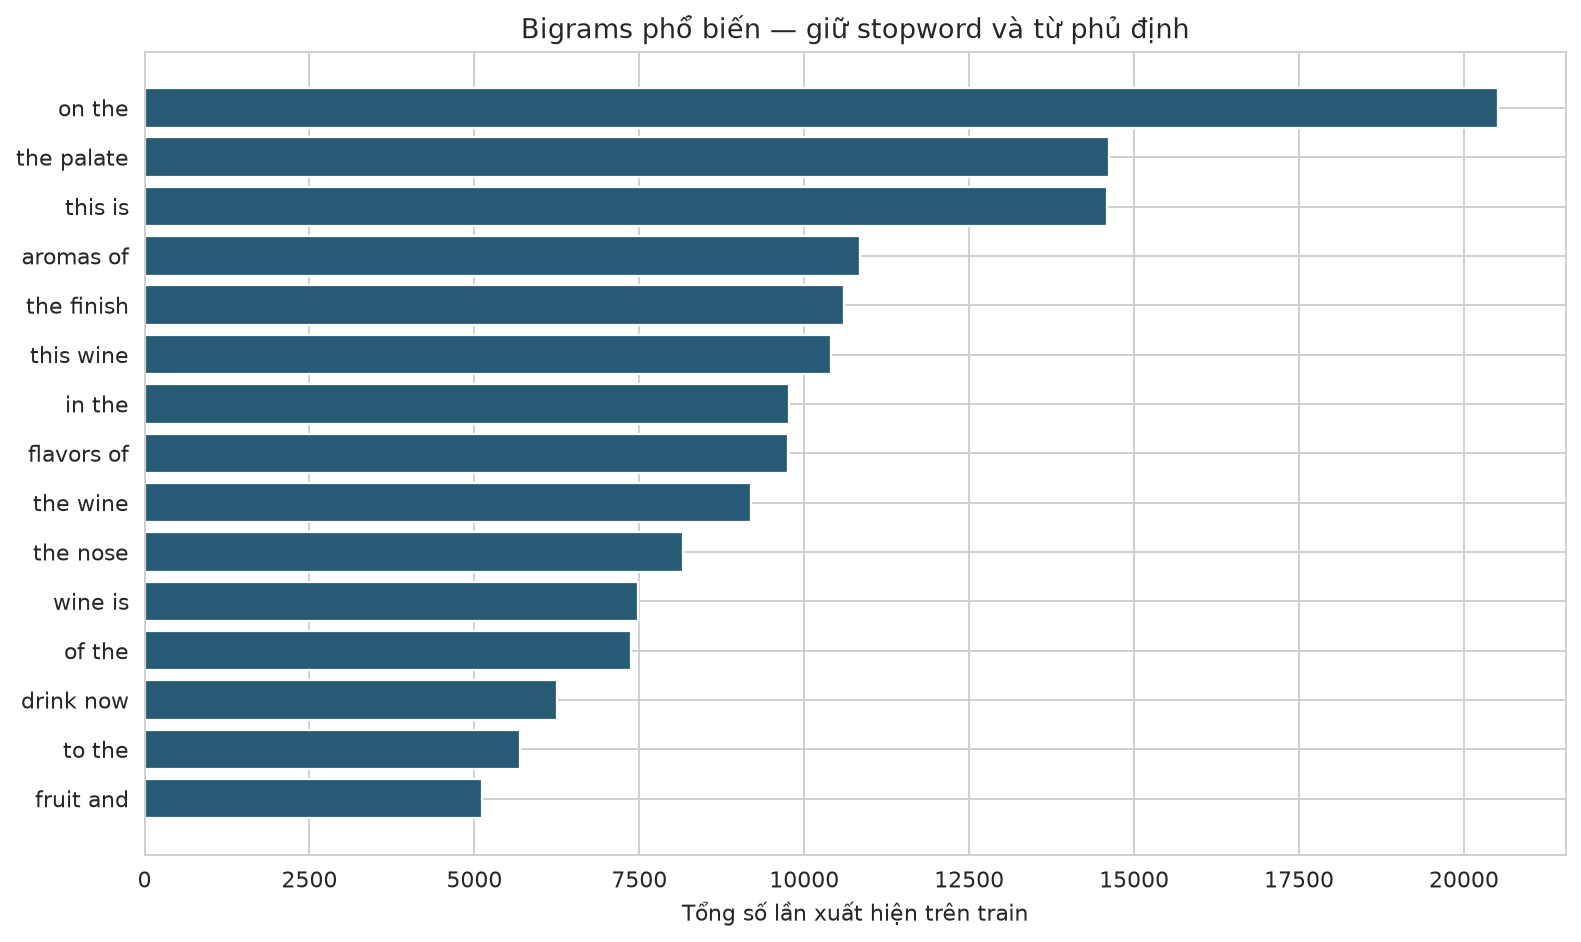

**Nhận xét:** train có độ dài review trung vị 40 từ; 29 review dưới 10 từ, 0 review trống. Độ dài khác nhau cần được cân nhắc khi xây TF-IDF; từ phổ biến không tự giải thích điểm số.

In [6]:
display(tables['review_summary'])
show_figure('05_review_length')
for kind in ['unigrams', 'bigrams']:
    display(tables[kind].head(15))
    show_figure(f'06_{kind}')
review = tables['review_summary'].iloc[0]
display(Markdown(f"**Nhận xét:** train có độ dài review trung vị {review.median_words:.0f} từ; "
    f"{int(review.under_10_words):,} review dưới 10 từ, {int(review.empty_reviews):,} review trống. "
    "Độ dài khác nhau cần được cân nhắc khi xây TF-IDF; từ phổ biến không tự giải thích điểm số."))

## 6. Audit trùng review giữa các tập

Chỉ kiểm tra chuỗi review chuẩn hóa, không xem nhãn holdout hoặc sửa phân bố split. Trùng theo nghĩa diễn đạt gần giống chưa được phát hiện bằng phép kiểm tra này.

In [7]:
display(tables['review_overlap'])
display(Markdown("**Giới hạn:** nếu có review dùng chung giữa train và holdout, kết quả văn bản về sau "
    "có thể lạc quan. Cần thống nhất biện pháp trước modeling; không tự chia lại trong EDA."))

,left,right,shared_unique_reviews
0,train,val,6
1,train,test,5
2,val,test,1


**Giới hạn:** nếu có review dùng chung giữa train và holdout, kết quả văn bản về sau có thể lạc quan. Cần thống nhất biện pháp trước modeling; không tự chia lại trong EDA.

## 7. Tổng hợp và bước tiếp theo

- Giá lệch phải và các nhóm metadata không cân bằng; cần giữ phân khúc giá cao và báo sai số theo nhóm.
- Bảng giá–điểm mô tả xu hướng, chưa chứng minh quan hệ nhân quả hoặc độ tin cậy của giá để mua hàng.
- Review chứa cách diễn đạt của người chấm. Dự đoán từ review phản ánh thông tin về điểm trong lời nhận xét đã có.
- Bước tiếp theo: kiểm định theo giả thuyết định trước; xây preprocessing chỉ fit trên train, TF-IDF unigram/bigram và Ridge; CV theo nhóm, validation rồi test sau khóa cấu hình.
- Chỉ một mô hình kết hợp chưa đo riêng được lợi ích của review. Muốn kết luận lợi ích tăng thêm phải có mô hình đối chiếu cùng split.
- Chưa có kết quả MAE, RMSE, R² hay kiểm định chính thức. EDA trước đây đã xem toàn mẫu; holdout seed 42 từng được thử, nên không mô tả test là hoàn toàn chưa từng được quan sát.

Bảng và hình được tạo lại trong `outputs/eda/`; không sửa số liệu bằng tay.